# Práctica 2 — Introducción al aprendizaje supervisado

**Machine Learning · Máster Universitario en Inteligencia Artificial · curso 2026/2027**

Grupo: *4* · Integrantes: *Carlos Chapman Peña*, *Miguel Ángel Gordillo Masero*, *María Xiaolan Ríos Díaz*, *Pablo Sola Díaz*

---

Cuaderno **de partida**. La primera celda de código fija vuestro grupo y vuestra semilla y carga
los datos; la última escribe los dos ficheros que subís a Kaggle. **Entre medias, el cuaderno es
vuestro**: los títulos de los ejercicios solo marcan el orden. La interpretación va en celdas
Markdown, no en comentarios de Python.

## 0. Entorno, semilla y datos

Declarad `GRUPO` y `SEMILLA` antes de nada. **Toda la aleatoriedad del cuaderno sale de
`SEMILLA`**: las particiones de la validación, los desempates y cualquier `random_state`.

In [2]:
# --- Práctica 2: grupo, semilla, entorno y datos --------------------------------
GRUPO = 4        # vuestro número de grupo (entero)
SEMILLA = 67      # vuestra semilla (entero): toda la aleatoriedad sale de aquí

import os, sys, platform
import numpy as np, pandas as pd, matplotlib, sklearn, scipy
import matplotlib.pyplot as plt

assert isinstance(GRUPO, int) and isinstance(SEMILLA, int), "Declarad GRUPO y SEMILLA (enteros) antes de seguir."

DATOS = os.path.join("..", "Datos")                  # relativa a este cuaderno
sys.path.insert(0, os.path.join("..", "Codigo"))     # código proporcionado por el curso
from oner import OneRClassifier, OneRRegressor
from comprobar_estimador import comprobar_estimador

ciber_train = pd.read_csv(os.path.join(DATOS, "ciber_train.csv"))
ciber_test = pd.read_csv(os.path.join(DATOS, "ciber_test.csv"))
latencia_train = pd.read_csv(os.path.join(DATOS, "latencia_train.csv"))
latencia_test = pd.read_csv(os.path.join(DATOS, "latencia_test.csv"))

X_CIBER = [c for c in ciber_test.columns if c != "id"]          # características de ciber
X_LATENCIA = [c for c in latencia_test.columns if c != "id"]    # características de latencia

print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("GRUPO       ", GRUPO, "· SEMILLA", SEMILLA)
print("ciber       ", ciber_train.shape, ciber_test.shape)
print("latencia    ", latencia_train.shape, latencia_test.shape)

python       3.12.10
numpy        1.26.4
pandas       2.2.3
scikit-learn 1.6.1
GRUPO        4 · SEMILLA 67
ciber        (5000, 13) (5000, 12)
latencia     (5000, 11) (3000, 10)


## Ejercicio 1. Cómo vais a medir



### 1(a) Datos de ciber_train

In [3]:
ciber_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            5000 non-null   object 
 1   proto         5000 non-null   object 
 2   service       5000 non-null   object 
 3   conn_state    5000 non-null   object 
 4   duration      5000 non-null   float64
 5   src_bytes     5000 non-null   int64  
 6   dst_bytes     5000 non-null   int64  
 7   missed_bytes  5000 non-null   int64  
 8   src_pkts      5000 non-null   int64  
 9   src_ip_bytes  5000 non-null   int64  
 10  dst_pkts      5000 non-null   int64  
 11  dst_ip_bytes  5000 non-null   int64  
 12  attack_type   5000 non-null   object 
dtypes: float64(1), int64(7), object(5)
memory usage: 507.9+ KB


Con `.info()` comprobamos que el conjunto de entrenamiento tiene 5000 patrones y 13 columnas, sin valores
ausentes. `id` es un identificador y no se usa como característica; `attack_type` es la variable objetivo.
Las 11 características restantes son de dos tipos:

| Tipo | Características |
|---|---|
| Nominales (3) | `proto`, `service`, `conn_state` |
| Numéricas (8) | `duration` (segundos, real) y siete recuentos enteros: `src_bytes`, `dst_bytes`, `missed_bytes`, `src_pkts`, `src_ip_bytes`, `dst_pkts`, `dst_ip_bytes` |

Al combinar tipos nominales y numéricos, para usar KNN habrá que decidir cómo representar las nominales para que
una distancia entre patrones tenga sentido (Ejercicio 3a).

In [4]:
NOM_CIBER = ["proto", "service", "conn_state"]
NUM_CIBER = [c for c in X_CIBER if c not in NOM_CIBER]

resumen = ciber_train[NUM_CIBER].describe(percentiles=[.25, .5, .75, .99]).T
resumen["% ceros"] = (ciber_train[NUM_CIBER] == 0).mean().mul(100).round(1)
resumen["asimetría"] = ciber_train[NUM_CIBER].skew().round(1)
display(resumen.drop(columns="count").round(2))

,mean,std,min,25%,50%,75%,99%,max,% ceros,asimetría
duration,7.24,39.31,0.0,0.0,0.19,0.4,152.81,1.801540e+03,1.4,23.5
src_bytes,447347.17,19451141.48,0.0,0.0,0.00,150.5,4839.02,9.516904e+08,51.1,46.3
dst_bytes,455961.87,19457025.58,0.0,0.0,0.00,285.0,12183.00,9.517448e+08,53.9,46.3
missed_bytes,449594.32,26707848.35,0.0,0.0,0.00,0.0,1251.97,1.854527e+09,98.2,67.4
src_pkts,34.52,72.72,0.0,1.0,4.00,100.0,120.00,2.828000e+03,8.1,15.7
src_ip_bytes,1692.95,3863.06,0.0,72.0,356.00,4800.0,6054.46,1.759590e+05,8.1,23.8
dst_pkts,2.70,20.63,0.0,0.0,1.00,2.0,17.00,1.311000e+03,38.6,53.2
dst_ip_bytes,1425.55,28928.45,0.0,0.0,60.00,340.0,12815.00,1.925805e+06,38.6,60.5


La tabla resume las 8 características numéricas, a las que añadimos el porcentaje de ceros y el coeficiente de
asimetría (0 para una distribución simétrica; positivo cuando hay una cola larga hacia valores altos).

**Escalas muy distintas.** Todas empiezan en 0, pero sus máximos van de unos $10^3$ (`duration`: 1801 s,
`src_pkts`: 2828) a unos $10^9$ (`src_bytes`: $9.5 \cdot 10^8$, `missed_bytes`: $1.9 \cdot 10^9$). Las
características en bytes tienen diferencias numéricamente mucho mayores que las de paquetes o duración.

**Distribuciones extremadamente asimétricas.** La asimetría va de 15.7 (`src_pkts`) a 67.4 (`missed_bytes`).
La mayoría de los patrones toman valores pequeños y unos pocos, valores enormes: en `src_bytes` la mediana
es 0, el percentil 99 es 4839 y la media, 447 347, **supera incluso al percentil 99**. La media y la desviación
típica no representan un patrón típico; la mediana y los percentiles sí.

**Muchos ceros.** `missed_bytes` vale 0 en el 98.2 % de los patrones, `src_bytes` y `dst_bytes` en más de la
mitad, y `dst_pkts` y `dst_ip_bytes` en el 38.6 %. Un cero aquí tiene significado (una conexión sin bytes de
respuesta, por ejemplo) y no es un valor ausente.

**Consecuencia para KNN.** La distancia euclídea suma diferencias al cuadrado de todas las características. Con
estas escalas, las características en bytes dominarían la distancia por su magnitud, no por ser más informativas,
y la cola de valores extremos haría que la mayoría de los patrones queden comprimidos cerca de 0. Cómo
transformar las numéricas es por tanto una decisión clave, que compararemos en el Ejercicio 3a.

,patrones,%
attack_type,,
normal,2998,59.96
xss,300,6.00
ddos,300,6.00
password,300,6.00
injection,300,6.00
dos,300,6.00
scanning,252,5.04
backdoor,100,2.00
mitm,100,2.00


Desbalanceo (mayoritaria / minoritaria): 60.0


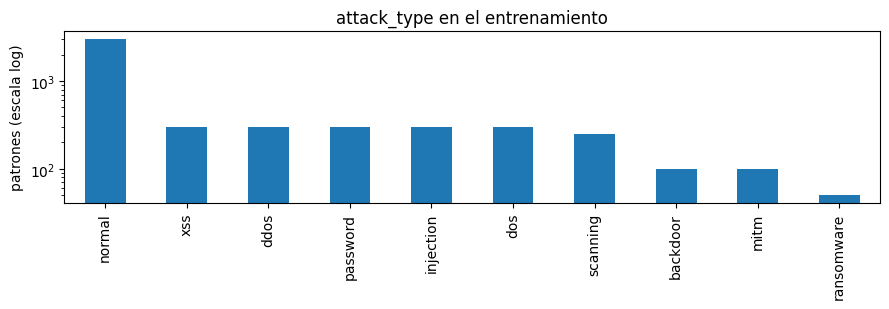

In [5]:
y_ciber = ciber_train["attack_type"]
dist = pd.DataFrame({"patrones": y_ciber.value_counts(),
                     "%": y_ciber.value_counts(normalize=True).mul(100).round(2)})
display(dist)
print(f"Desbalanceo (mayoritaria / minoritaria): {dist['patrones'].max() / dist['patrones'].min():.1f}")

fig, ax = plt.subplots(figsize=(9, 3.2))
dist["patrones"].plot.bar(ax=ax, color="C0")
ax.set_yscale("log"); ax.set_ylabel("patrones (escala log)"); ax.set_xlabel("")
ax.set_title("attack_type en el entrenamiento")
plt.tight_layout(); plt.show()

La variable objetivo, `attack_type`, tiene 10 clases: tráfico `normal` y nueve tipos de ataque. Su distribución
está muy desbalanceada:

| Grupo | Clases | Patrones por clase | % |
|---|---|---:|---:|
| Mayoritaria | `normal` | 2998 | 60.0 |
| Intermedias | `xss`, `ddos`, `password`, `injection`, `dos` | 300 | 6.0 |
| | `scanning` | 252 | 5.0 |
| Raras | `backdoor`, `mitm` | 100 | 2.0 |
| | `ransomware` | 50 | 1.0 |

La clase mayoritaria tiene 60 veces más patrones que la minoritaria. Según el enunciado, el test mantiene estas
proporciones, así que en él las clases raras también serán muy pocas y su F1 se calculará con muy pocos patrones.

**Por qué importa con esta métrica.** El F1 macro es la media sin ponderar del F1 de las diez clases:
`ransomware`, con 50 patrones, pesa en la puntuación exactamente lo mismo que `normal`, con 2998. Un modelo
que acierte casi todo el tráfico normal pero falle las clases raras tendrá una exactitud (CCR) alta y un F1
macro bajo. Esto tiene dos consecuencias:
- La CCR aparentemente no nos aportaría la información que necesitamos para comparar modelos en este problema. Podemos validar está idea más adelante. 
- Con tan pocos patrones de las clases raras, el protocolo de validación tiene que asegurar que todas las
  clases aparezcan en cada partición de validación, en su proporción.

In [6]:
for c in NOM_CIBER:
    print(f"\n{c}: {ciber_train[c].nunique()} categorías")
    display(pd.crosstab(ciber_train[c], y_ciber, margins=True, margins_name="total"))


proto: 3 categorías


attack_type,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss,total
proto,,,,,,,,,,,
icmp,0,0,0,0,6,15,0,0,0,0,21
tcp,100,214,253,288,44,1424,299,50,228,265,3165
udp,0,86,47,12,50,1559,1,0,24,35,1814
total,100,300,300,300,100,2998,300,50,252,300,5000



service: 8 categorías


attack_type,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss,total
service,,,,,,,,,,,
-,96,183,247,35,17,1355,26,50,223,95,2327
dce_rpc,1,0,0,0,0,0,0,0,0,0,1
dns,0,86,47,12,48,1500,0,0,24,35,1752
ftp,0,0,0,0,0,0,11,0,0,0,11
http,0,24,1,253,4,102,262,0,1,170,817
smb,2,0,0,0,0,0,0,0,0,0,2
smb;gssapi,1,0,0,0,0,0,0,0,0,0,1
ssl,0,7,5,0,31,41,1,0,4,0,89
total,100,300,300,300,100,2998,300,50,252,300,5000



conn_state: 13 categorías


attack_type,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss,total
conn_state,,,,,,,,,,,
OTH,0,2,0,1,6,23,0,49,0,5,86
REJ,96,0,175,0,0,0,24,0,217,0,512
RSTO,0,0,30,2,3,13,0,0,5,0,53
RSTOS0,0,0,0,0,1,2,0,0,0,3,6
RSTR,3,0,0,0,3,8,7,0,0,37,58
RSTRH,0,0,0,0,0,4,0,0,0,5,9
S0,0,3,41,0,1,1766,1,0,1,26,1839
S1,0,91,0,7,0,1,0,0,0,14,113
S2,0,1,0,7,1,2,0,0,0,2,13


Las tablas cruzan cada característica nominal con la clase. La columna `total` da la frecuencia de cada categoría.

**Cardinalidad y categorías raras.** `proto` tiene 3 categorías, `service` 8 y `conn_state` 13. Varias son
muy poco frecuentes: en `proto`, `icmp` (21 patrones); en `service`, `ftp` (11), `smb` (2), `dce_rpc` y
`smb;gssapi` (1 cada una); en `conn_state`, `RSTOS0` (6).

**Algunas categorías casi identifican una clase:**
- 49 de los 50 patrones de `ransomware` tienen `conn_state = OTH`.
- Los 11 patrones con `service = ftp` son `password`.
- Los 4 patrones con `smb`, `dce_rpc` o `smb;gssapi` son `backdoor`.
- `conn_state = S0` (1839 patrones) es casi exclusivamente `normal` (1766).

**Otras mezclan varias clases:**
- `conn_state = REJ` agrupa `scanning` (217), `dos` (175), `backdoor` (96) y `password` (24).
- `service = http` agrupa `password` (262), `injection` (253) y `xss` (170).

**Consecuencias.** Las nominales son muy informativas, pero ninguna separa por sí sola todas las clases: dentro
de `REJ` o de `http`, la distinción tendrá que venir de otras características. Además, al ser categorías sin orden,
habrá que representarlas de forma que una distancia entre patrones tenga sentido (Ejercicio 3a), teniendo en
cuenta que algunas categorías tienen muy pocos patrones. Las clases que comparten categorías (`scanning`, `dos`,
`backdoor` en `REJ`; `password`, `injection`, `xss` en `http`) son candidatas a confundirse entre sí, lo que
comprobaremos en la matriz de confusión (Ejercicio 3c).

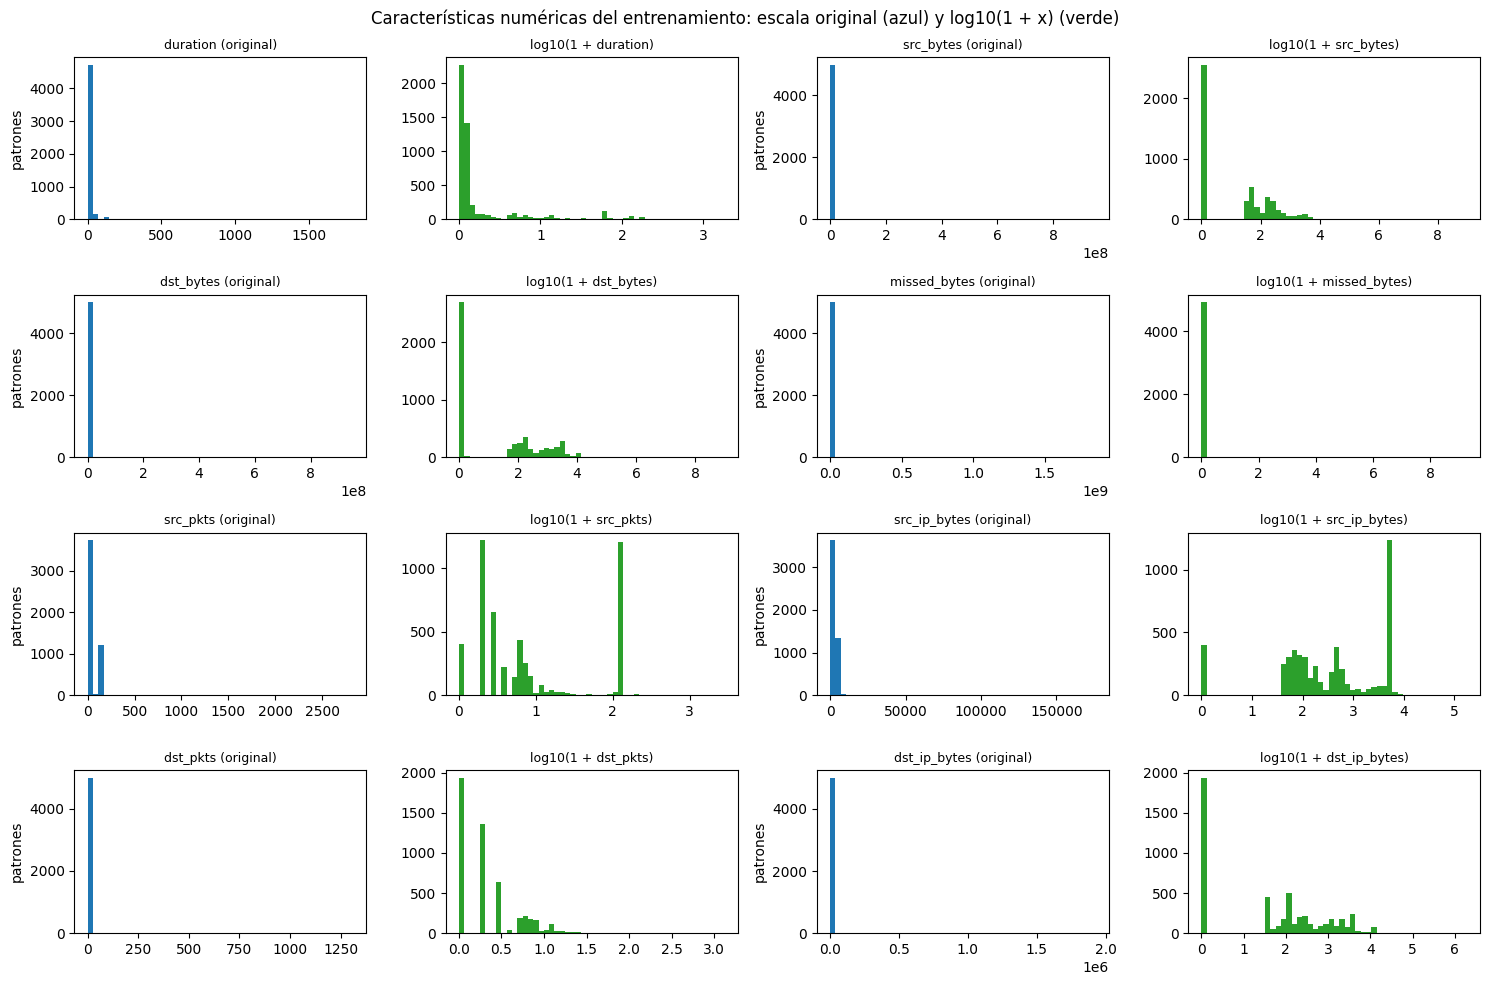

In [7]:
fig, axs = plt.subplots(4, 4, figsize=(15, 10))
for i, c in enumerate(NUM_CIBER):
    ax_orig, ax_log = axs[i // 2, 2 * (i % 2)], axs[i // 2, 2 * (i % 2) + 1]
    ax_orig.hist(ciber_train[c], bins=50, color="C0")
    ax_orig.set_title(f"{c} (original)", fontsize=9)
    ax_log.hist(np.log10(ciber_train[c] + 1), bins=50, color="C2")
    ax_log.set_title(f"log10(1 + {c})", fontsize=9)
for ax in axs[:, [0, 2]].ravel():
    ax.set_ylabel("patrones")
fig.suptitle("Características numéricas del entrenamiento: escala original (azul) y log10(1 + x) (verde)")
plt.tight_layout(); plt.show()

Los histogramas muestran las 8 numéricas en escala original (azul) y en escala $\log_{10}(1+x)$ (verde).

**Por qué esta transformación.** Los valores van de 0 a $10^9$, así que en escala original casi todo queda
aplastado junto al 0. El logaritmo convierte esas diferencias multiplicativas en diferencias sumadas, de forma
que cada orden de magnitud ocupa el mismo espacio en el eje: de 10 a 100 bytes se ve igual que de $10^6$ a $10^7$.
El problema es que $\log_{10}(0)$ no está definido, y muchas de estas características valen 0 en gran parte de
los patrones. Sumar 1 antes del logaritmo lo resuelve: un 0 se representa en 0 y, para valores grandes, sumar 1
apenas cambia el resultado. Aquí la usamos solo para visualizar los datos; si conviene usarla como
preprocesamiento se decidirá en el Ejercicio 3a.

En escala original no se distingue la distribución: casi todos los patrones se concentran junto al 0 y unos
pocos valores extremos estiran el eje. Solo en `src_pkts` y `src_ip_bytes` se aprecia una segunda barra, que
analizamos en la celda siguiente.

La escala logarítmica permite ver la forma, que sigue lejos de ser simétrica:
- En las características de **bytes** hay una gran masa de ceros y, separado, un grupo de conexiones con datos.
  `missed_bytes` es prácticamente siempre 0.
- En las de **paquetes** los valores son enteros pequeños y forman barras aisladas, con un pico muy marcado en
  `src_pkts` (y en `src_ip_bytes`).
- `duration` concentra casi todo cerca de 0, con una cola de conexiones largas.

**Consecuencia.** El logaritmo reduce mucho la diferencia de escalas, pero no elimina las masas de ceros ni los
picos. Qué transformación funciona mejor para KNN no se deduce de estas figuras: se decidirá comparando opciones
con validación en el Ejercicio 3a.

In [8]:
# El pico del histograma de src_ip_bytes es su valor más frecuente (la moda), no su máximo
pico_bytes = ciber_train["src_ip_bytes"].mode()[0]
filas_pico = ciber_train[ciber_train["src_ip_bytes"] == pico_bytes]
print(f"Valor más frecuente de src_ip_bytes: {pico_bytes} bytes, en {len(filas_pico)} patrones")

# ¿Cuántos paquetes tienen esas conexiones y a qué clase pertenecen?
display(filas_pico["src_pkts"].value_counts().to_frame().T)
display(filas_pico["attack_type"].value_counts().to_frame().T)
print(f"Fracción del tráfico normal: {len(filas_pico) / (y_ciber == 'normal').sum():.1%}")

Valor más frecuente de src_ip_bytes: 4800 bytes, en 1203 patrones


src_pkts,120
count,1203


attack_type,normal
count,1203


Fracción del tráfico normal: 40.1%


La barra más alta del histograma de `src_ip_bytes` corresponde a su valor más frecuente (no a su máximo):
4800 bytes, que aparece en 1203 patrones. Esos 1203 patrones tienen todos 120 paquetes, lo que explica también
la barra aislada de `src_pkts`, y todos son tráfico `normal`: el 40 % de todo el tráfico normal envía exactamente
4800 bytes en 120 paquetes.

**Consecuencia para KNN.** Esa zona del espacio estará muy poblada y será muy homogénea: un patrón con ese
perfil tendrá muchos vecinos `normal` a distancia casi nula. El tráfico normal no es una única nube, sino
al menos un bloque muy compacto y otro más disperso.

In [9]:
# Mediana de cada numérica por clase: cómo es una conexión típica de cada tipo
display(ciber_train.groupby("attack_type")[NUM_CIBER].median().round(2).T)

attack_type,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss
duration,0.0,0.16,0.0,0.22,0.21,0.21,0.01,0.0,0.02,5.2
src_bytes,0.0,0.00,0.0,258.50,168.00,0.00,155.00,0.0,0.00,1943.5
dst_bytes,0.0,0.00,0.0,1951.00,436.00,0.00,978.00,0.0,0.00,1218.5
missed_bytes,0.0,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.0
src_pkts,1.0,2.00,2.0,5.00,4.00,4.00,5.00,1.0,1.00,6.0
src_ip_bytes,48.0,112.00,80.0,528.00,280.00,488.00,421.00,435.0,44.00,2114.0
dst_pkts,1.0,1.00,1.0,6.00,3.00,0.00,5.00,0.0,1.00,4.0
dst_ip_bytes,40.0,86.00,44.0,2239.00,492.00,0.00,1150.00,0.0,40.00,1320.5


La tabla muestra el **perfil numérico** de cada clase. Cada columna es una clase y cada fila una característica;
cada valor es la mediana de esa característica entre los patrones de esa clase, es decir, el valor que deja la mitad
de sus conexiones por debajo y la otra mitad por encima. Por ejemplo, la columna de `backdoor` indica que la mitad de
sus conexiones envían 1 paquete o menos y 48 bytes o menos. Leer una columna entera da una idea de cómo es una
conexión habitual de ese tipo de ataque. Usamos la mediana y no la media porque, con distribuciones tan asimétricas,
unos pocos valores extremos pueden afectar mucho a la media.

- Las numéricas **distinguen algunas clases**: `xss`, `injection`, `password` y `mitm` son las únicas que
  intercambian datos (`src_bytes` y `dst_bytes` distintos de 0), y `xss` es la que más bytes envía y la que más dura.
  Esto ayuda a separar las clases que comparten `service = http`
- Otras clases **son casi indistinguibles**: `backdoor` y `scanning` tienen un perfil prácticamente idéntico,
  conexiones de 1 paquete y unos 40–48 bytes sin datos. Como además comparten `conn_state = REJ`, es de esperar
  que se confundan entre sí
- Algunas características **apenas aportan**: `missed_bytes` tiene mediana 0 en todas las clases

**Consecuencia.** No todas las características son igual de útiles para distinguir las clases, y algunas solo lo
son para ciertos pares de clases. Esto puede ser útil e importante al decidir cómo se construye la distancia de KNN, en el
preprocesamiento y en el diseño de nuestra variante.

In [10]:
print("Patrones con características repetidas en el entrenamiento:",
      ciber_train.duplicated(subset=X_CIBER).sum())

Patrones con características repetidas en el entrenamiento: 0


No hay dos patrones de entrenamiento con exactamente las mismas características: cada fila es una conexión
distinta. No hay grupos de filas relacionadas que debamos mantener juntas al validar.

**Finalmente** 


*¿Qué hace difícil este problema?*

1. **Desbalanceo con F1 macro.** `ransomware` (50 patrones) pesa en la métrica lo mismo que `normal` (2998). Un
   modelo que falle las clases raras tendrá una CCR alta y un F1 macro bajo. La CCR no sirve para comparar
   modelos, y el protocolo tiene que asegurar que las clases raras aparezcan en cada partición de
   validación.
2. **Escalas muy distintas y distribuciones muy asimétricas.** Las numéricas van de $10^3$ a $10^9$, con muchos
   ceros y picos. Sin transformar, las de bytes dominarían la distancia de KNN por su magnitud. La transformación de las numéricas se decidirá comparando opciones.
3. **Tipos mezclados.** Hay tres nominales, algunas con categorías de muy pocos patrones, que hay que representar
   para que una distancia tenga sentido. Codificación de las nominales.
4. **Clases que se solapan.** `scanning`, `dos` y `backdoor` comparten `conn_state = REJ`, y `backdoor` y `scanning`
   tienen además un perfil numérico casi idéntico; `password`, `injection` y `xss` comparten `service = http`. Lo comprobaremos en la matriz de confusión.
5. **Sin duplicados ni grupos.** Cada fila es una conexión independiente. Basta una partición estratificada; no
   hace falta validación agrupada.

### 1(b) Protocolos de validación — ciberseguridad

In [11]:
from sklearn.model_selection import KFold, StratifiedKFold

CLASES_RARAS = ["ransomware", "backdoor", "mitm"]
X_c = ciber_train[X_CIBER]

filas = []
for nombre, cv in [("KFold", KFold(n_splits=5, shuffle=True, random_state=SEMILLA)),
                   ("StratifiedKFold", StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA))]:
    for q, (_, idx_val) in enumerate(cv.split(X_c, y_ciber), start=1):
        cuenta = y_ciber.iloc[idx_val].value_counts()
        filas.append({"esquema": nombre, "partición": q, **{c: cuenta.get(c, 0) for c in CLASES_RARAS}})

reparto = pd.DataFrame(filas).set_index(["esquema", "partición"])
display(reparto)
display(reparto.groupby("esquema").agg(["min", "max"]))

ransomware  backdoor  mitm
esquema         partición                            
KFold           1                   8        17    26
                2                   7        21    21
                3                  18        17    17
                4                   7        27    17
                5                  10        18    19
StratifiedKFold 1                  10        20    20
                2                  10        20    20
                3                  10        20    20
                4                  10        20    20
                5                  10        20    20

ransomware     backdoor     mitm    
                       min max      min max  min max
esquema                                             
KFold                    7  18       17  27   17  26
StratifiedKFold         10  10       20  20   20  20

Antes de elegir los protocolos candidatos comprobamos con los datos si hace falta estratificar, en lugar de darlo por supuesto.

**¿Hace falta estratificar?** Contamos cuántos patrones de cada clase rara caen en cada partición de validación de
una validación cruzada con 5 particiones, sin estratificar (`KFold`) y estratificada (`StratifiedKFold`).

Sin estratificar, el número de patrones de `ransomware` por partición va de 7 a 18: una partición tiene más del
doble que otra, por puro azar. Como el F1 macro da a `ransomware` el mismo peso que a `normal`, el F1 de cada
partición dependería en buena medida de cuántos `ransomware` le hayan tocado. Con estratificación, todas las
particiones tienen exactamente 10 `ransomware`, 20 `backdoor` y 20 `mitm`: las mismas proporciones que el
entrenamiento y, según el enunciado, que el test. Por eso todos los protocolos que comparamos a continuación son
estratificados.

**Protocolos candidatos.** De las estrategias de validación del Tema 4 comparamos cuatro, todas estratificadas:
- **Hold-out 80/20**: la opción más barata; sirve para comprobar si basta con un único corte.
- **Validación cruzada con 5 particiones** y **con 10 particiones**: los compromisos habituales entre el tamaño del
  entrenamiento de cada ronda y el de cada partición de validación, que aquí importa mucho: con 10 particiones,
  cada una contiene solo 5 patrones de `ransomware`.
- **Validación cruzada con 5 particiones repetida 3 veces (5×3)**: promedia tres particiones distintas de los datos
  para que la estimación dependa menos de un único reparto, manteniendo 10 `ransomware` por partición.

Descartamos el resto: la validación sin estratificar, por el experimento anterior; la validación agrupada, porque
no hay grupos ni duplicados (comprobado en el 1a), leave-one-out, porque exige 5000 ajustes y el F1 macro de un único patrón no tiene
sentido; y el bootstrap, porque cada modelo se entrenaría con solo un 63 % aproximado de patrones distintos.

**Cómo los comparamos.** Para que un protocolo produzca una cifra hace falta un modelo que genere predicciones; de
él no se ajusta ni se elige nada. Usamos dos KNN con K = 5 y las nominales en one-hot: el de la referencia del
enunciado (sin escalar) y el mismo con las numéricas estandarizadas. El primero está definido en el enunciado; el
segundo se parece más a los modelos que compararemos en los Ejercicios 3 a 5, que llevarán preprocesamiento. Si
ambos llevan al mismo protocolo, la elección no depende del modelo de prueba.

Cada protocolo se evalúa con 10 semillas distintas, derivadas de `SEMILLA`, y la métrica es el F1 macro de la
competición. No buscamos el protocolo que dé la cifra más alta, sino el más estable: si la estimación cambia mucho
al cambiar la semilla, no podremos distinguir dos modelos parecidos.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedShuffleSplit, RepeatedStratifiedKFold, cross_val_score
import time

def knn5(escalar):
    """KNN K=5 de prueba: one-hot en las nominales y, si escalar=True, numéricas estandarizadas."""
    numericas = StandardScaler() if escalar else "passthrough"
    pre = ColumnTransformer([("nom", OneHotEncoder(handle_unknown="ignore"), NOM_CIBER),
                             ("num", numericas, NUM_CIBER)])
    return Pipeline([("pre", pre), ("knn", KNeighborsClassifier(n_neighbors=5))])

MODELOS_PRUEBA = {"KNN5 sin escalar": knn5(False), "KNN5 estandarizado": knn5(True)}

PROTOCOLOS = {   # nombre: (función que crea el particionado a partir de una semilla, nº de ajustes)
    "hold-out 80/20": (lambda s: StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=s), 1),
    "5-fold":         (lambda s: StratifiedKFold(n_splits=5, shuffle=True, random_state=s), 5),
    "10-fold":        (lambda s: StratifiedKFold(n_splits=10, shuffle=True, random_state=s), 10),
    "5-fold ×3":      (lambda s: RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=s), 15),
}

N_SEMILLAS = 10
semillas = np.random.default_rng(SEMILLA).integers(0, 10**6, size=N_SEMILLAS)   # todas salen de SEMILLA

filas = []
for nombre_modelo, modelo in MODELOS_PRUEBA.items():
    for nombre_prot, (crear_cv, n_ajustes) in PROTOCOLOS.items():
        t0 = time.perf_counter()
        estimaciones = [cross_val_score(modelo, ciber_train[X_CIBER], y_ciber, cv=crear_cv(int(s)),
                                        scoring="f1_macro").mean() for s in semillas]
        filas.append({"modelo": nombre_modelo, "protocolo": nombre_prot, "ajustes": n_ajustes,
                      "F1 macro (media)": np.mean(estimaciones),
                      "desv. entre semillas": np.std(estimaciones, ddof=1),
                      "mín": np.min(estimaciones), "máx": np.max(estimaciones),
                      "tiempo (s)": (time.perf_counter() - t0) / N_SEMILLAS})

tabla_protocolos = pd.DataFrame(filas).set_index(["modelo", "protocolo"])
display(tabla_protocolos.round(4))

ajustes  F1 macro (media)  \
modelo             protocolo                                   
KNN5 sin escalar   hold-out 80/20        1            0.8532   
                   5-fold                5            0.8551   
                   10-fold              10            0.8610   
                   5-fold ×3            15            0.8551   
KNN5 estandarizado hold-out 80/20        1            0.9015   
                   5-fold                5            0.8965   
                   10-fold              10            0.9020   
                   5-fold ×3            15            0.8968   

                                   desv. entre semillas     mín     máx  \
modelo             protocolo                                              
KNN5 sin escalar   hold-out 80/20                0.0164  0.8279  0.8698   
                   5-fold                        0.0040  0.8483  0.8617   
                   10-fold                       0.0037  0.8556  0.8679   
                   5-fold ×3                     0.0026  0.8515  0.8595   
KNN5 estandarizado hold-out 80/20                0.0108  0.8874  0.9161   
                   5-fold                        0.0030  0.8914  0.9013   
                   10-fold                       0.0019  0.8996  0.9059   
                   5-fold ×3                     0.0021  0.8938  0.8993   

                                   tiempo (s)  
modelo             protocolo                   
KNN5 sin escalar   hold-out 80/20      0.1646  
                   5-fold              0.0898  
                   10-fold             0.1413  
                   5-fold ×3           0.2731  
KNN5 estandarizado hold-out 80/20      0.0238  
                   5-fold              0.0962  
                   10-fold             0.1508  
                   5-fold ×3           0.2705

**Resultado.** Con los dos modelos de prueba, el hold-out es claramente el menos fiable: su estimación cambia entre
4 y 6 veces más que la de los demás al cambiar la semilla (desviación 0.0164 sin escalar y 0.0108 estandarizado). Con
el KNN sin escalar, según qué patrones caigan en validación, la misma cifra puede ser 0.828 o 0.870: una diferencia
mayor que la que habrá entre muchos de los modelos que queremos comparar. Lo descartamos.

Entre los otros tres, el 5-fold simple es el menos estable con ambos modelos. El 10-fold y el 5×3 quedan muy
parecidos, y el orden cambia según el modelo: sin escalar es más estable el 5×3 (0.0026 frente a 0.0037) y
estandarizado lo es el 10-fold (0.0019 frente a 0.0021). El coste no decide: todos tardan menos de un segundo por
estimación.

**Elección: validación cruzada estratificada con 5 particiones, repetida 3 veces (5×3), con F1 macro.**
- Es el protocolo más estable *en el peor caso*: su desviación no pasa de 0.0026 con ninguno de los dos modelos,
  mientras que la del 10-fold llega a 0.0037. Como todavía no sabemos qué preprocesamiento tendrán nuestros
  modelos, preferimos el protocolo que mide bien en ambos casos.
- Cada partición de validación contiene 10 patrones de `ransomware` frente a los 5 del 10-fold, así que el F1 de
  cada partición es menos ruidoso. Esto importa para la dispersión entre particiones que mostraremos en la curva
  de validación de K.
- Reproduce la construcción del test, que mantiene las proporciones de clases del entrenamiento.

La estimación de un modelo será la media del F1 macro de las 15 particiones, acompañada de su dispersión. Las
particiones se fijan con `SEMILLA` y son las mismas para todos los modelos que comparemos, de forma que las
comparaciones sean emparejadas.

In [13]:
# Protocolo elegido para ciberseguridad: se usa en todos los ejercicios siguientes
CV_CIBER = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)

### 1(c) Fuga de información — ciberseguridad

Hay fuga de información cuando algo que se aprende de los datos se aprende usando también la partición de
validación: esa partición deja de ser "datos no vistos" y la estimación deja de representar lo que pasará con el
test. En nuestro protocolo hay cinco puntos por los que podría colarse información, y cómo lo evitamos en cada uno:

1. **El preprocesamiento de las numéricas.** Un escalado guarda valores aprendidos de los datos (la media y la
   desviación típica, por ejemplo). Si se ajustara con los 5000 patrones antes de partir, los patrones de validación
   influirían en cómo se transforman ellos mismos. Para evitarlo, todo el preprocesamiento va dentro de un `Pipeline`
   junto al modelo: la validación cruzada lo vuelve a ajustar en cada ronda solo con la parte de entrenamiento, y
   después lo aplica sin cambios a la partición de validación.

2. **La codificación de las nominales.** El codificador one-hot aprende la lista de categorías. También va dentro del
   `Pipeline`, y lo configuramos para que ignore las categorías que no vio al ajustarse (`handle_unknown="ignore"`).
   Esto no es un caso teórico: categorías con un único patrón, como `dce_rpc` o `smb;gssapi` (1a), caerán en alguna
   ronda en la partición de validación sin estar en la de entrenamiento. El codificador las trata como desconocidas,
   igual que haría con una categoría nueva del test.

3. **Nuestro KNN propio (Ejercicio 4).** Si nuestra variante aprende algo de los datos (pesos, frecuencias de clase,
   patrones que se eliminan…), lo calculará dentro de su método `fit`, que en cada ronda solo recibe la parte de
   entrenamiento.

4. **Patrones repetidos.** Si un patrón estuviera en entrenamiento y una copia suya en validación, KNN lo encontraría
   a distancia 0 y lo acertaría sin mérito. En ciberseguridad no ocurre: no hay patrones con características
   repetidas (1a), y por eso no necesitamos una validación agrupada.

5. **Elegir la configuración con la misma validación con la que la medimos.** Aunque cada ronda esté limpia, si
   comparamos muchas configuraciones y nos quedamos con la de mejor F1, parte de su ventaja será suerte de las
   particiones, y esa cifra será optimista (Tema 4). Para limitarlo: compararemos pocos candidatos, fijados de
   antemano; elegiremos con una regla enunciada, sin perseguir diferencias menores que la dispersión entre
   particiones; y no usaremos la clasificación pública de Kaggle para decidir. El test solo se usa en la última
   celda, para predecir.

### 1(a) Datos de latencia_train

In [14]:
# Información general
latencia_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             5000 non-null   object 
 1   block_size     5000 non-null   int64  
 2   n_jobs         5000 non-null   int64  
 3   iodepth        5000 non-null   int64  
 4   read_fraction  5000 non-null   int64  
 5   load_type      5000 non-null   object 
 6   io_type        5000 non-null   object 
 7   raid           5000 non-null   object 
 8   n_disks        5000 non-null   int64  
 9   device_type    5000 non-null   object 
 10  latency_ns     5000 non-null   float64
dtypes: float64(1), int64(5), object(5)
memory usage: 429.8+ KB


Con .info() comprobamos que no hay valores nulos en ninguna de las características del conjunto de datos y podemos ver el tipo de dato de cada una.

In [15]:
display(latencia_train.describe())

nominales = ['load_type', 'io_type', 'raid', 'device_type']
for col in nominales:
    print(latencia_train[col].value_counts())
    print("\n")

,block_size,n_jobs,iodepth,read_fraction,n_disks,latency_ns
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,208.576000,16.88100,16.934000,40.684000,17.994000,2.407129e+07
std,301.354501,15.54494,10.060412,36.357097,6.719598,9.319971e+07
min,4.000000,1.00000,1.000000,0.000000,3.000000,1.143315e+05
25%,16.000000,6.00000,8.000000,0.000000,12.000000,6.099692e+05
50%,64.000000,12.00000,15.000000,35.000000,20.000000,1.240523e+06
75%,256.000000,20.00000,27.000000,75.000000,24.000000,8.127825e+06
max,1024.000000,64.00000,32.000000,100.000000,24.000000,1.262194e+09


load_type
random        3270
sequential    1730
Name: count, dtype: int64


io_type
write    2980
read     2020
Name: count, dtype: int64


raid
4+1    2180
2+2     600
4+2     565
8+2     560
1+1     560
2+1     535
Name: count, dtype: int64


device_type
nvme    4210
hdd      790
Name: count, dtype: int64




Con .describe() mostramos un resumen estadístico de las características, que incluye la media, la desviación típica, los cuartiles y los valores mínimos y máximos. A partir de estos últimos, podemos observar que las características tienen escalas bastante diferentes. Por ejemplo, `block_size` toma valores entre 4 y 1024, mientras que los valores de `latency_ns` son mucho más elevados, llegando hasta 1.262.194.000. Otras variables, como `n_jobs` e `iodepth`, tienen rangos más reducidos. Estas diferencias de escala deben tenerse en cuenta durante el preprocesamiento, porque puede ser necesario aplicar técnicas de normalización o estandarización antes de entrenar el modelo.

Por otro lado, las variables categóricas muestran distribuciones desiguales: en `load_type` predomina random (3.270) frente a sequential (1.730); en `io_type` también hay más registros de write (2.980) que de read (2.020); en `raid` destaca 4+1 como la configuración más frecuente (2.180), mientras que las demás tienen frecuencias similares, con valores entre 535 y 600 registros; y en `device_type` domina claramente nvme (4.210) sobre hdd (790).

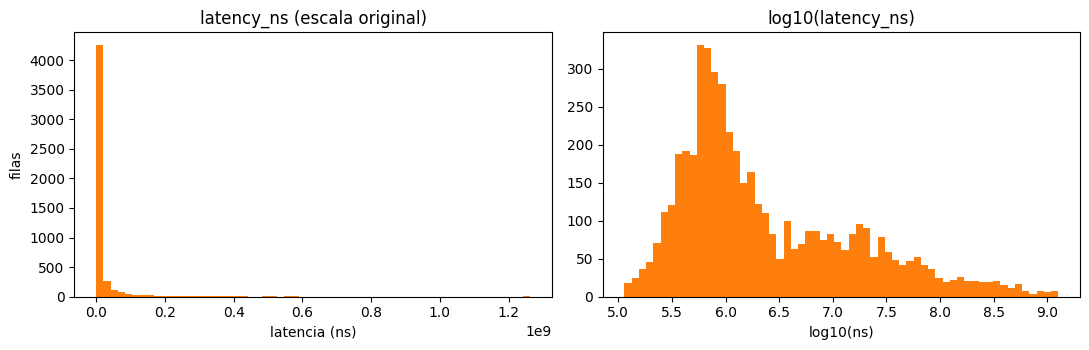

In [16]:
# Distribución de la variable objetivo (latencia_ns) en train
y = latencia_train["latency_ns"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(y, bins=60, color="C1"); ax[0].set_title("latency_ns (escala original)")
ax[0].set_xlabel("latencia (ns)"); ax[0].set_ylabel("filas")
ax[1].hist(np.log10(y), bins=60, color="C1"); ax[1].set_title("log10(latency_ns)")
ax[1].set_xlabel("log10(ns)")
plt.tight_layout(); plt.show()

En las gráficas podemos observar la distribución de la variable objetivo (`latency_ns`) tanto en su escala original como después de aplicar la transformación logarítmica `log10`.

En la escala original, la distribución es muy asimétrica hacia la derecha, ya que la mayoría de las observaciones tienen valores bajos, mientras que existen algunos valores de latencia muy altos que alargan la distribución.

Al aplicar la transformación logarítmica, reducimos esta asimetría y visualizamos mejor la distribución de los datos. De esta forma, podemos observar con más claridad las diferencias entre las latencias y conocer mejor el comportamiento de la variable antes de utilizarla en el modelo.

In [17]:
# Cuánto varían las cinco ejecuciones de una misma configuración

# Se definen las columnas que representan la "configuración" (todas menos 'id' y 'latency_ns')
configuracion = [c for c in latencia_train.columns if c not in ['id', 'latency_ns']]

grupos_lat = latencia_train.groupby(configuracion)["latency_ns"]
ratio_max_min = grupos_lat.max() / grupos_lat.min()
std_log10 = grupos_lat.apply(lambda s: np.log10(s).std(ddof=1))

resumen_var = pd.DataFrame({
    "ratio_max_min": ratio_max_min,
    "std_log10_ns": std_log10,
})
print("Resumen de variabilidad entre las 5 ejecuciones (1.000 configuraciones):")
display(
    resumen_var.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T[[
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "90%",
        "max",
    ]]
)

# Ejemplo de una configuración y sus 5 latencias distintas
ejecuciones = grupos_lat.size()
ejemplo = ejecuciones[ejecuciones == 5].index[0]
ejemplo = (latencia_train[configuracion] == ejemplo).all(axis=1)
ejemplo = latencia_train[ejemplo][['block_size', 'n_jobs', 'iodepth', 'read_fraction', 'load_type', 'io_type', 'raid', 'n_disks', 'device_type', 'latency_ns']]
print("\nEjemplo de las 5 ejecuciones para una misma configuración:")
display(ejemplo)
latencias = ejemplo['latency_ns']

Resumen de variabilidad entre las 5 ejecuciones (1.000 configuraciones):


,count,mean,std,min,25%,50%,75%,90%,max
ratio_max_min,1000.0,1.287067,1.139653,1.000245,1.021795,1.068416,1.223296,1.572391,26.24800
std_log10_ns,1000.0,0.030703,0.053001,0.000044,0.003833,0.011891,0.035911,0.080515,0.62397



Ejemplo de las 5 ejecuciones para una misma configuración:


,block_size,n_jobs,iodepth,read_fraction,load_type,io_type,raid,n_disks,device_type,latency_ns
408,4,2,11,23,random,read,4+1,24,nvme,121127.5
543,4,2,11,23,random,read,4+1,24,nvme,117519.0
3819,4,2,11,23,random,read,4+1,24,nvme,116699.0
4349,4,2,11,23,random,read,4+1,24,nvme,119568.5
4960,4,2,11,23,random,read,4+1,24,nvme,118525.0


La primera tabla muestra cuánto varía la latencia (`latency_ns`) entre las 5 repeticiones de cada una de las 1.000 configuraciones únicas. Para ello, se utilizan dos métricas:
* **`ratio_max_min`**: indica cuántas veces mayor es la latencia máxima respecto a la mínima de una misma configuración. Un valor cercano a 1 significa que las ejecuciones han tenido resultados muy similares, mientras que valores más altos indican una mayor diferencia entre ellas.
* **`std_log10_ns`**: mide la desviación típica de `log10(latency_ns)` dentro de cada configuración. Permite analizar la variabilidad teniendo en cuenta que las diferencias de latencia pueden ser multiplicativas y no siempre siguen una distribución simétrica.

### Resumen de variabilidad

En la mayoría de las configuraciones se observa una variabilidad bastante baja entre las cinco repeticiones. La mediana (`50%`) de `ratio_max_min` es 1.068, lo que significa que, en un caso típico, la ejecución más lenta tarda aproximadamente un 6,8 % más que la más rápida. Además, en el `75 %` de las configuraciones el ratio no supera 1.223. La mediana de `std_log10_ns` también es baja (0.0119), lo que confirma que, por lo general, las distintas ejecuciones ofrecen resultados bastante similares.

Sin embargo, hay algunas configuraciones que presentan diferencias mucho más importantes entre repeticiones. Esto se refleja en que la media de `ratio_max_min` (1.287) es superior a su mediana (1.068), lo que indica que existen algunos valores extremos que elevan el promedio. Aunque la mayoría de los casos son bastante estables, el percentil 90 alcanza 1.572 y el valor máximo llega a 26.248. Esto significa que, en alguna configuración concreta, la ejecución más lenta ha tardado más de 26 veces que la más rápida.

Estos resultados muestran que una misma configuración no siempre produce exactamente la misma latencia, ya que existen variaciones entre sus distintas ejecuciones, probablemente debido a la existencia de ruido.

### Ejemplo

La segunda tabla muestra un ejemplo concreto de la variabilidad de la latencia en las cinco ejecuciones de una configuración. En este caso, se puede ver que no varía demasiado.

**¿Qué hace difícil este problema?**

La predicción de la latencia es difícil debido a diferentes cosas:

- **Asimetría de su distribución:** La variable objetivo tiene un rango de valores muy amplio (desde aproximadamente $10^5$ hasta $10^9$ ns) y una distribución muy sesgada. Esto es importante porque el $MAE_{\log}$ calcula el error absoluto medio sobre el logaritmo decimal de la latencia:
   $$MAE_{\log} = \frac{1}{n} \sum_{i=1}^{n} \vert{}\log_{10} y_i - \log_{10} \hat{y}_i\vert{}$$
   A diferencia del $MAE$, que mide las diferencias absolutas en las unidades originales y hace que los errores en valores más altos tengan mayor peso, el $MAE_{\log}$ tiene en cuenta los errores relativos. De esta forma, evita que las latencias más elevadas condicionen tanto el resultado de la evaluación. Esto significa que un error multiplicativo del mismo tamaño (por ejemplo, desviarse por un factor de 1.26) recibe la misma penalización, independientemente de si se produce en latencias de microsegundos o de milisegundos.

- **La variabilidad entre ejecuciones de una misma configuración:** Como hemos visto en la tabla anterior, los resultados de las cinco repeticiones de una misma configuración varían un poco debido al ruido, lo que planteará la decisión de si entrenar el modelo con todas las filas o calcular un valor medio que represente cada configuración en el Ejercicio 3.

- **Que puedan existir relaciones no lineales e interacciones entre las características:** El rendimiento del almacenamiento depende de varios factores que se influyen entre sí, como el tamaño de bloque, la profundidad de cola, el número de hilos y el tipo de RAID. Por ello, es necesario utilizar modelos que puedan detectar cómo afectan sus distintas combinaciones al rendimiento.

- **Hay variables numéricas y categóricas:** Como el conjunto de datos combina ambos tipos de variables, es necesario realizar un preprocesamiento adecuado antes de entrenar el modelo. Para ello, se deberán transformar las variables categóricas mediante técnicas de codificación y escalar las numéricas para evitar que unas tengan más peso que otras. Esto es muy importante en KNN porque utiliza distancias para determinar qué configuraciones son más similares entre sí.

### 1(b) Protocolos de validación de latencia_train

In [18]:
from sklearn.model_selection import GroupKFold, KFold

# Identificador de grupo: cada configuración única de hardware/carga (1.000 grupos)
cols_config = [c for c in X_LATENCIA]
grupos_latencia = latencia_train.groupby(cols_config, dropna=False).ngroup()

# Métrica oficial de la competición: error absoluto medio en log10(latency_ns)
def mae_log(y_true, y_pred):
  y_true = np.asarray(y_true, dtype=float)
  y_pred = np.asarray(y_pred, dtype=float)
  assert np.all(y_true > 0) and np.all(y_pred > 0), (
      "y_true y y_pred deben ser positivos"
  )
  return float(np.mean(np.abs(np.log10(y_true) - np.log10(y_pred))))


# Esquemas de validación candidatos (K = 5 particiones)
cv_agrupada = GroupKFold(n_splits=5)
cv_aleatoria = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Comprobación de solapamiento de configuraciones entre train y validación
solap_agrupada = []
solap_aleatoria = []

for tr_idx, va_idx in cv_agrupada.split(
    latencia_train, latencia_train["latency_ns"], groups=grupos_latencia
):
  solap_agrupada.append(
      len(
          set(grupos_latencia.iloc[tr_idx]) & set(grupos_latencia.iloc[va_idx])
      )
  )

for tr_idx, va_idx in cv_aleatoria.split(latencia_train):
  solap_aleatoria.append(
      len(
          set(grupos_latencia.iloc[tr_idx]) & set(grupos_latencia.iloc[va_idx])
      )
  )

print(
    "Configuraciones compartidas train/val por fold (GroupKFold, K=5):",
    solap_agrupada,
)
print(
    "Configuraciones compartidas train/val por fold (KFold por filas, K=5):",
    solap_aleatoria,
)

Configuraciones compartidas train/val por fold (GroupKFold, K=5): [0, 0, 0, 0, 0]
Configuraciones compartidas train/val por fold (KFold por filas, K=5): [684, 681, 677, 669, 657]


### Esquemas de validación que vamos a probar
Utilizamos 5 particiones ($K = 5$) sobre el conjunto de entrenamiento y comparamos dos formas de realizar la validación:

- **1º Validación cruzada aleatoria por filas:** divide las 5.000 filas al azar sin tener en cuenta las configuraciones, por lo que una misma configuración puede aparecer tanto en entrenamiento como en validación.


- **2º Validación cruzada por grupos:** agrupa las filas según su configuración, definida por sus 9 características. Así, las cinco ejecuciones de una configuración caen siempre en la misma partición, evitando que una configuración aparezca tanto en entrenamiento como en validación.

### Métrica utilizada
La métrica que usaremos para medir la calidad del modelo será $MAE_{\log}$, que es la de la competición. Cuanto menor sea su valor, mejor será el resultado, siempre que las predicciones sean positivas:
$$MAE_{\log} = \frac{1}{n} \sum_{i=1}^{n} \vert{}\log_{10} y_i - \log_{10} \hat{y}_i\vert{}$$


### Elección y justificación
Al validar sin agrupar por configuración, obtendremos un $MAE_{\log}$ más bajo que el de la validación cuando se agrupan, siendo más optimista. Esto es debido a lo siguiente: 

De cada grupo de configuración (denotemos a un grupo de ejemplo como $G1$), tenemos 5 ejecuciones distintas. Si en el grupo de entrenamiento de $G1$ caen solo dos ejecuciones ($G1_{1}$ y $G1_{2}$), las otras tres caerán en el grupo de validación ($G1_{3}$, $G1_{4}$ y $G1_{5}$). Entonces, cuando el modelo reciba, por ejemplo $G1_{3}$, verá que está a distancia cero de $G1_{1}$ y $G1_{2}$, por lo que estará evaluándose sobre configuraciones que ya conoce.

Además, con el código anterior comprobamos que, agrupando por configuración, no se comparte ninguna configuración entre los conjuntos de entrenamiento y validación en ninguna de las cinco particiones. En cambio, sin agrupar, se comparten entre 657 y 684 configuraciones en cada partición, lo que confirma que existe un solapamiento importante entre ambos conjuntos.

Sin embargo, el conjunto de test contiene 600 configuraciones nuevas (3000 filas) que no aparecen en el entrenamiento. Por esto, seleccionaremos la validación cruzada por grupos con 5 particiones, ya que reproduce mejor las condiciones que encontraremos en la competición. Aunque el error obtenido sea algo mayor que con la división aleatoria por filas, tendremos una estimación más realista de cómo se comportará el modelo con configuraciones que no ha visto. Con 5 particiones, en cada una deja unas 200 configuraciones en validación (unas 1000 filas) y unas 800 configuraciones en entrenamiento (unas 4000 filas).

In [19]:

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, StratifiedGroupKFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Variables que vamos a utilizar
nominales = ["load_type", "io_type", "raid", "device_type"]
numericas = ["block_size", "n_jobs", "iodepth", "read_fraction", "n_disks"]

lat = latencia_train.copy()
lat["ylog"] = np.log10(lat["latency_ns"])

# Identificamos las configuraciones
lat["grupo"] = grupos_lat.ngroup()

# Dividimos las configuraciones en 5 grupos según su latencia media
media_config = lat.groupby("grupo")["ylog"].mean() #agrupo en grupos de config y extraigo su media
bins = pd.qcut(media_config, 5, labels=False)  #Dividimos las 1000 config en 5 grupos segun su media 
lat["bin"] = lat["grupo"].map(bins) #Asignamos a cada fila el grupo de latencia al que pertenece su configuración.

X_lat = lat[configuracion]
y_lat = lat["ylog"]

# Creamos las particiones para los dos protocolos
n_part = 5

filas = list(KFold(n_splits=n_part, shuffle=True, random_state=SEMILLA).split(X_lat))

grupos = list(
    StratifiedGroupKFold(n_splits=n_part, shuffle=True, random_state=SEMILLA).split(X_lat, lat["bin"], lat["grupo"]))


# Función para crear el modelo KNN con su preprocesamiento
def crear_knn(k):
    preprocesamiento = ColumnTransformer([("numericas", StandardScaler(), numericas),
        ("nominales", OneHotEncoder(handle_unknown="ignore"), nominales)])
    modelo = Pipeline([ ("preprocesamiento", preprocesamiento),
        ("knn", KNeighborsRegressor(n_neighbors=k)) ])
    return modelo

# Calculamos el MAE en escala logarítmica para cada partición
def calcular_mae(k, particiones):
    resultados = cross_val_score(crear_knn(k), X_lat,y_lat,cv=particiones,scoring="neg_mean_absolute_error" )
    return -resultados


# Comparamos los dos protocolos para distintos valores de K
resultados = []

for k in [1,2,3,4,5,6,7,8,9,10]:
    mae_filas = calcular_mae(k, filas)
    mae_grupos = calcular_mae(k, grupos)
    resultados.append({ "K": k, "MAE_filas": mae_filas.mean(),"std_filas": mae_filas.std(),
                       "MAE_grupos": mae_grupos.mean(),"std_grupos": mae_grupos.std() })

comparacion_protocolos = pd.DataFrame(resultados)
comparacion_protocolos


,K,MAE_filas,std_filas,MAE_grupos,std_grupos
0,1,0.033623,0.001514,0.252916,0.012990
1,2,0.033509,0.001070,0.252284,0.011704
2,3,0.042123,0.002444,0.251845,0.010336
3,4,0.065220,0.004903,0.251401,0.010916
4,5,0.095581,0.005849,0.251498,0.010578
5,6,0.118549,0.006347,0.232904,0.005931
6,7,0.134279,0.006024,0.225574,0.004778
7,8,0.143141,0.005482,0.223872,0.005284
8,9,0.148150,0.005356,0.225288,0.006229
9,10,0.151264,0.005690,0.227298,0.006215


### 1(c) Fugas de información de latencia_train 

En nuestro protocolo de validación, hemos identificado tres posibles situaciones en las que podría producirse una fuga de información entre los datos de entrenamiento y los de validación.

**1. Las cinco ejecuciones de cada configuración.**

Cada configuración tiene cinco ejecuciones. Si dividiéramos los datos sin tener esto en cuenta, algunas ejecuciones de una misma configuración podrían quedar en entrenamiento y otras en validación. Esto haría que el modelo se evaluara con configuraciones que ya ha visto durante el entrenamiento (fuga de información), obteniendo una estimación del error más optimista de lo que realmente sería.

Como hemos visto en el apartado 1(b), evitamos este problema utilizando la validación cruzada agrupada por configuración, así las cinco ejecuciones de cada configuración siempre permanecen juntas en la misma partición.

**2. El preprocesamiento de los datos.**

Al preparar los datos, transformaciones como escalar (calcular medias y desviaciones típicas de las características numéricas) o codificar variables categóricas aprenden parámetros de los datos. Si hacemos esto antes de dividir en particiones, estaríamos utilizando indirectamente información de validación durante el entrenamiento. Por ejemplo, si queremos estandarizar datos y hacemos validación cruzada, separamos primero en entrenamiento y validación, y luego al conjunto de entrenamiento de cada iteración le calculamos la media y la desviación típica de cada característica para estandarizar tanto el entrenamiento como la validación (restando esa media y dividiendo por esa desviación). Si calculásemos esos parámetros a partir de todo el conjunto antes de dividir, habríamos obtenido información del conjunto de validación en el preprocesamiento, del cual el modelo no debería saber nada.

Para evitarlo, encapsulamos todo el preprocesamiento y el modelo dentro de un pipeline antes de pasarlo a la validación cruzada, lo que garantiza que cada transformación se ajuste únicamente con los datos de entrenamiento de cada partición.

**3. Uso de los datos de test y resultados de Kaggle.**

Si utilizáramos el conjunto de test para ajustar las transformaciones, lo consultáramos antes de la última celda o cambiáramos el modelo después de ver los resultados de Kaggle, estaríamos utilizando información que no debemos tener en cuenta durante el entrenamiento ni en la selección del modelo.

Para evitarlo, seguimos las indicaciones de la práctica y utilizamos únicamente la validación cruzada agrupada sobre latencia_train para elegir los modelos y ajustar sus hiperparámetros. El conjunto latencia_test solo se utiliza en la última celda, donde realizamos las predicciones una vez reajustados los modelos finales.

## Ejercicio 2. Modelos de referencia: ZeroR y OneR


### 2(a) ZeroR — ciberseguridad

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, f1_score, cohen_kappa_score

# Metricas de ciber: se decide con F1 macro. CCR y kappa se calculan como complemento
METRICAS_CIBER = {"f1_macro": make_scorer(f1_score, average="macro", zero_division=0, pos_label=None),
                  "ccr": "accuracy",
                  "kappa": make_scorer(cohen_kappa_score)}

zeror = DummyClassifier(strategy="most_frequent")
res_zeror = cross_validate(zeror, ciber_train[X_CIBER], y_ciber, cv=CV_CIBER, scoring=METRICAS_CIBER)

print("Clase que predice ZeroR:", zeror.fit(ciber_train[X_CIBER], y_ciber).classes_[np.argmax(zeror.class_prior_)])
tabla_zeror = pd.DataFrame({m: [res_zeror[f"test_{m}"].mean(), res_zeror[f"test_{m}"].std(ddof=1)]
                            for m in METRICAS_CIBER}, index=["media", "desv. entre particiones"])
display(tabla_zeror.round(4))

Clase que predice ZeroR: normal


,f1_macro,ccr,kappa
media,0.075,0.5996,0.0
desv. entre particiones,0.000,0.0005,0.0


**ZeroR** ignora las características y predice siempre la clase más frecuente del entrenamiento de cada ronda:
`normal`. Lo evaluamos con nuestro protocolo (5×3 estratificado).

**CCR frente a F1 macro.** Como anticipamos en el 1a, la CCR engaña en este problema por el desbalanceo de clases.
ZeroR acierta el 60 % de los patrones (CCR = 0.600), una cifra que parece aceptable, y sin embargo su F1 macro es
solo 0.075. La razón se puede calcular a mano:
- Para `normal`, la exhaustividad es 1 (encuentra todos) y la precisión 0.6 (de lo que predice, el 60 % es
  `normal`), así que su F1 es $2 \cdot 0.6 \cdot 1 / (0.6 + 1) = 0.75$.
- Para las otras nueve clases el F1 es 0, porque nunca las predice.
- El F1 macro es la media de las diez: $0.75 / 10 = 0.075$.

La CCR solo refleja el tamaño de la clase mayoritaria: un modelo que no ha aprendido nada obtiene un 60 %. Por eso
no sirve para comparar modelos en este problema, y el F1 macro sí lo detecta. El kappa de Cohen lo confirma: vale
exactamente 0, ningún acuerdo por encima del que darían las frecuencias de clase por azar.

La desviación entre particiones es prácticamente 0: como la validación es estratificada, todas las particiones
tienen la misma proporción de `normal` y ZeroR obtiene la misma puntuación en todas.

En las nueve clases que ZeroR nunca predice, la precisión es 0/0 (no está definida); la tomamos como 0
(`zero_division=0`), que es la convención habitual, y la declaramos explícitamente.

### 2(b) OneR — ciberseguridad

**Qué validamos.** OneR construye una regla por cada característica ("si vale esto, predice esta clase") y se queda
con la que menos se equivoca en el entrenamiento. Con una nominal, cada categoría es un grupo. Una numérica, en
cambio, se corta antes en tramos, y cada tramo es un grupo: `n_bins` es el número de tramos que se piden. Usamos la
estrategia por defecto de `oner.py`, que corta por cuantiles para que cada tramo tenga un número parecido de patrones.
Con valores muy repetidos, varios cortes caen en el mismo punto y se fusionan: por ejemplo, como `missed_bytes` vale 0
en el la mayoría de los patrones, casi todos sus cuantiles valen 0. Por eso los tramos reales pueden ser que no aporten información correcta.

**Qué esperamos.** Al aumentar `n_bins`, el error de entrenamiento de las numéricas debería bajar: partir un tramo
en dos, cada uno con su clase mayoritaria, no tiene sentido que acierte menos patrones de entrenamiento. El de validación no tiene por
qué: con tramos muy finos, la clase mayoritaria de cada uno se decide con pocos patrones y realmente esa clase aparece por cómo fue la partición, es decir no se controla, por lo que si te sale una buena partición puede ser casualidad y suerte. Lo
esperable es que el F1 de validación mejore al principio y quizás pare de mejorar, o incluso empeore, a partir de cierto punto.

**Cómo elegimos.** Fijamos la regla antes de ver los resultados: el menor `n_bins` cuyo F1 macro medio esté a menos de
una desviación del mejor (el más alto) Si otro valor está muy cerca esa ventaja puede deberse al ruido. A modo de "desempate" entre valores que solo difieren en el "ruido", preferimos la regla con menos tramos.
La regla no confía ciegamente en el más alto. Lo usa como referencia para ver quién está empatado con él, y entre los empatados elige el más sencillo.
Solo cuando la diferencia es clara, mayor que la desviación, se puede decir que el más alto es mejor de verdad.

In [21]:
# Más tramos que valores distintos no añade cortes nuevos: esto acota el rango de n_bins que tiene sentido probar
valores_distintos = ciber_train[NUM_CIBER].nunique().sort_values(ascending=False)
display(valores_distintos.to_frame("valores distintos").T)

,duration,src_ip_bytes,dst_ip_bytes,src_bytes,dst_bytes,src_pkts,missed_bytes,dst_pkts
valores distintos,4740,745,620,573,541,82,56,46


In [22]:
def intervalos_reales(v, n_bins):
    """Nº de tramos que quedan tras fusionar los cortes por cuantiles repetidos (como hace oner.py)."""
    if n_bins == 1:
        return 1
    return len(np.unique(np.quantile(v, np.linspace(0, 1, n_bins + 1)[1:-1]))) + 1

display(pd.DataFrame({nb: {c: intervalos_reales(ciber_train[c].to_numpy(float), nb) for c in NUM_CIBER}
                      for nb in [10, 100, 1000]}).rename(columns=lambda nb: f"n_bins = {nb}"))

,n_bins = 10,n_bins = 100,n_bins = 1000
duration,10,100,988
src_bytes,6,44,243
dst_bytes,6,38,214
missed_bytes,2,3,16
src_pkts,7,16,45
src_ip_bytes,9,61,306
dst_pkts,6,13,30
dst_ip_bytes,8,43,235


In [23]:
# Valores repartidos en escala logarítmica, de 1 hasta el máximo de valores distintos
N_BINS = np.unique(np.round(np.logspace(0, np.log10(valores_distintos.max()), 16)).astype(int))
print("Valores de n_bins que probamos:", N_BINS.tolist())

filas = []
for nb in N_BINS:
    res = cross_validate(OneRClassifier(n_bins=int(nb)), ciber_train[X_CIBER], y_ciber, cv=CV_CIBER,
                         scoring=METRICAS_CIBER, return_estimator=True)
    elegidas = pd.Series([m.feature_name_ for m in res["estimator"]]).value_counts()   # qué eligió en cada ronda
    filas.append({"n_bins": nb, "F1 macro": res["test_f1_macro"].mean(),
                  "desv.": res["test_f1_macro"].std(ddof=1), "CCR": res["test_ccr"].mean(),
                  "característica elegida (rondas)": ", ".join(f"{c} ({n})" for c, n in elegidas.items())})

curva_oner = pd.DataFrame(filas).set_index("n_bins")
display(curva_oner.round(4))

Valores de n_bins que probamos: [1, 2, 3, 5, 10, 17, 30, 52, 91, 160, 282, 496, 872, 1533, 2696, 4740]


,F1 macro,desv.,CCR,característica elegida (rondas)
n_bins,,,,
1,0.3357,0.0135,0.7001,conn_state (15)
2,0.3357,0.0135,0.7001,conn_state (15)
3,0.3357,0.0135,0.7001,conn_state (15)
5,0.3357,0.0135,0.7001,conn_state (15)
10,0.3357,0.0135,0.7001,conn_state (15)
17,0.3357,0.0135,0.7001,conn_state (15)
30,0.4654,0.0404,0.7149,"src_ip_bytes (14), dst_ip_bytes (1)"
52,0.4489,0.0784,0.7481,"dst_ip_bytes (9), src_ip_bytes (6)"
91,0.5736,0.0132,0.7775,src_ip_bytes (15)


Mejor F1: n_bins = 872 (0.6563 +/- 0.0178)
Umbral (mejor - 1 desviación): 0.6385   n_bins elegido: 496


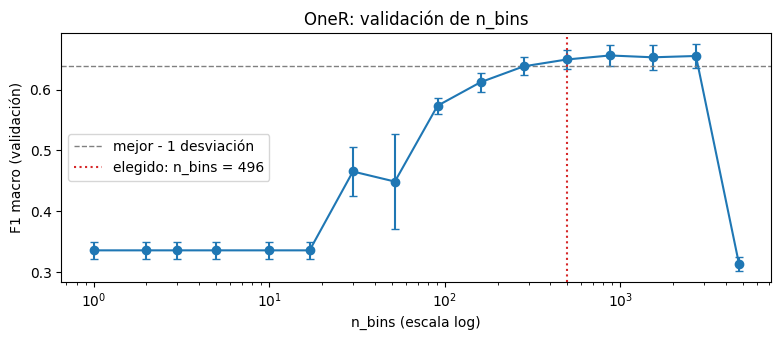

In [25]:
mejor = curva_oner["F1 macro"].idxmax()
umbral = curva_oner.loc[mejor, "F1 macro"] - curva_oner.loc[mejor, "desv."]
n_bins_elegido = curva_oner.index[curva_oner["F1 macro"] >= umbral].min()
print(f"Mejor F1: n_bins = {mejor} ({curva_oner.loc[mejor, 'F1 macro']:.4f} +/- {curva_oner.loc[mejor, 'desv.']:.4f})")
print(f"Umbral (mejor - 1 desviación): {umbral:.4f}   n_bins elegido: {n_bins_elegido}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(curva_oner.index, curva_oner["F1 macro"], yerr=curva_oner["desv."], marker="o", capsize=3)
ax.axhline(umbral, color="grey", ls="--", lw=1, label="mejor - 1 desviación")
ax.axvline(n_bins_elegido, color="C3", ls=":", label=f"elegido: n_bins = {n_bins_elegido}")
ax.set_xscale("log"); ax.set_xlabel("n_bins (escala log)"); ax.set_ylabel("F1 macro (validación)")
ax.set_title("OneR: validación de n_bins"); ax.legend(); plt.tight_layout(); plt.show()

In [26]:
# Error de entrenamiento de la regla de cada característica, ajustando OneR con todo el entrenamiento
errores_oner = pd.DataFrame({nb: OneRClassifier(n_bins=int(nb)).fit(ciber_train[X_CIBER], y_ciber).errors_
                             for nb in N_BINS})
display(errores_oner.round(3))

,1,2,3,5,10,17,30,52,91,160,282,496,872,1533,2696,4740
proto,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400
service,0.365,0.365,0.365,0.365,0.365,0.365,0.365,0.365,0.365,0.365,0.365,0.365,0.365,0.365,0.365,0.365
conn_state,0.299,0.299,0.299,0.299,0.299,0.299,0.299,0.299,0.299,0.299,0.299,0.299,0.299,0.299,0.299,0.299
duration,0.400,0.400,0.400,0.400,0.400,0.396,0.382,0.366,0.352,0.343,0.329,0.318,0.298,0.268,0.215,0.049
src_bytes,0.400,0.400,0.400,0.400,0.374,0.334,0.332,0.314,0.292,0.279,0.265,0.261,0.255,0.245,0.237,0.225
dst_bytes,0.400,0.400,0.400,0.400,0.400,0.375,0.352,0.323,0.312,0.285,0.250,0.239,0.231,0.220,0.211,0.198
missed_bytes,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.400,0.396,0.395,0.395,0.394,0.392,0.390
src_pkts,0.400,0.400,0.400,0.400,0.377,0.357,0.356,0.352,0.350,0.351,0.349,0.347,0.346,0.345,0.344,0.342
src_ip_bytes,0.400,0.400,0.400,0.400,0.356,0.320,0.282,0.261,0.215,0.173,0.157,0.135,0.129,0.116,0.105,0.080
dst_pkts,0.400,0.400,0.400,0.384,0.369,0.358,0.357,0.338,0.338,0.335,0.335,0.334,0.333,0.334,0.333,0.332


In [27]:
for nb in [10, n_bins_elegido]:
    regla = OneRClassifier(n_bins=int(nb)).fit(ciber_train[X_CIBER], y_ciber).describe().splitlines()
    print(f"\n--- n_bins = {nb}: {len(regla) - 2} tramos o categorías en la regla")
    print("\n".join(regla[:16] + (["  ..."] if len(regla) > 16 else [])))


--- n_bins = 10: 13 tramos o categorías en la regla
OneR eligió la característica «conn_state» (error de entrenamiento 0.2990).
  conn_state = OTH  ->  ransomware
  conn_state = REJ  ->  scanning
  conn_state = RSTO  ->  dos
  conn_state = RSTOS0  ->  xss
  conn_state = RSTR  ->  xss
  conn_state = RSTRH  ->  xss
  conn_state = S0  ->  normal
  conn_state = S1  ->  ddos
  conn_state = S2  ->  injection
  conn_state = S3  ->  xss
  conn_state = SF  ->  normal
  conn_state = SH  ->  xss
  conn_state = SHR  ->  normal
  cualquier otro valor  ->  normal

--- n_bins = 496: 190 tramos o categorías en la regla
OneR eligió la característica «src_ip_bytes» (error de entrenamiento 0.1348).
  src_ip_bytes [0, 40)  ->  normal
  src_ip_bytes [40, 44)  ->  dos
  src_ip_bytes [44, 48)  ->  scanning
  src_ip_bytes [48, 52)  ->  backdoor
  src_ip_bytes [52, 56)  ->  backdoor
  src_ip_bytes [56, 58)  ->  normal
  src_ip_bytes [58, 59)  ->  normal
  src_ip_bytes [59, 60)  ->  normal
  src_ip_bytes [60, 

## Ejercicio 3. KNN de scikit-learn

*(TODO)*

## Ejercicio 4. Vuestro KNN clasificador y la competición de ciberseguridad

*(TODO)*

## Ejercicio 5. Vuestro KNN regresor y la competición de latencia

*(TODO)*

## Envío final

**Esta debe ser la última celda del cuaderno.** Entrena vuestros dos modelos finales, que llevan
dentro vuestro KNN propio, con **todo** el conjunto de entrenamiento y escribe los dos ficheros.
Si en latencia entrenáis con un resumen de las cinco ejecuciones de cada configuración, calculadlo
aquí, en `X_final_latencia` e `y_final_latencia`. Lo que subáis a Kaggle como envío final tiene que
ser exactamente lo que escribe esta celda: el profesor volverá a ejecutar el cuaderno y lo
comprobará. No cambiéis los nombres de los modelos ni de los ficheros.

In [17]:
# --- ENVÍO FINAL: esta celda es la ÚLTIMA del cuaderno ---------------------------
modelo_final_ciber = None   # TODO: vuestro Pipeline con vuestro KNN clasificador
modelo_final_latencia = None   # TODO: vuestro Pipeline con vuestro KNN regresor

# Datos de entrenamiento de los modelos finales: todo el entrenamiento.
X_final_ciber, y_final_ciber = ciber_train[X_CIBER], ciber_train["attack_type"]
X_final_latencia, y_final_latencia = latencia_train[X_LATENCIA], latencia_train["latency_ns"]

modelo_final_ciber.fit(X_final_ciber, y_final_ciber)
modelo_final_latencia.fit(X_final_latencia, y_final_latencia)

envio_ciber = pd.DataFrame({"id": ciber_test["id"],
                            "attack_type": modelo_final_ciber.predict(ciber_test[X_CIBER])})
envio_latencia = pd.DataFrame({"id": latencia_test["id"],
                               "latency_ns": modelo_final_latencia.predict(latencia_test[X_LATENCIA])})
assert (envio_latencia["latency_ns"] > 0).all(), "la latencia predicha tiene que ser positiva"
envio_ciber.to_csv("envio_ciber.csv", index=False)
envio_latencia.to_csv("envio_latencia.csv", index=False)
print("envio_ciber.csv   ", envio_ciber.shape)
print("envio_latencia.csv", envio_latencia.shape)

AttributeError: 'NoneType' object has no attribute 'fit'